# Qual é o melhor plano?

Você trabalha como analista para a empresa de telecomunicações Megaline. A empresa oferece aos clientes dois planos pré-pagos: Surf e Ultimate. O departamento comercial quer saber qual dos planos gera mais receita para ajustar o orçamento de publicidade.

Você vai realizar uma análise preliminar dos planos com base em uma pequena seleção de clientes. Você terá dados de 500 clientes da Megaline: que clientes são, de onde eles são, qual plano usam e o número de chamadas e mensagens realizadas em 2018. Seu trabalho é analisar o comportamento dos clientes e determinar qual plano pré-pago gera mais receita.

[Fornecemos alguns comentários para guiar sua linha de raciocínio enquanto você trabalha neste projeto. Entretanto, certifique-se de remover todos os comentários entre colchetes antes de enviar o projeto.]

[Antes de começar a análise dos dados, explique com suas próprias palavras o propósito do projeto e as ações que planeja realizar.]

[Tenha em mente que estudar, modificar e analisar dados é um processo iterativo. É normal retornar a etapas anteriores e corrigir/expandir algo para permitir as próximas etapas.]

In [1]:
## Inicialização

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statistics import mode, StatisticsError
from scipy import stats
from math import comb
from scipy.stats import norm, ttest_1samp, ttest_ind, ttest_rel, levene
# Carregando todas as bibliotecas



## Carregue os dados

In [3]:
calls = pd.read_csv('/datasets/megaline_calls.csv')
internet = pd.read_csv('/datasets/megaline_internet.csv')
messages = pd.read_csv('/datasets/megaline_messages.csv')
plans = pd.read_csv('/datasets/megaline_plans.csv')
users = pd.read_csv('/datasets/megaline_users.csv')# Carregue os arquivos de dados em diferentes DataFrames


## Prepare os dados

[Os dados deste projeto estão divididos em várias tabelas. Explore cada uma para obter uma compreensão inicial dos dados. Faça correções em cada tabela, se necessário.]

## Planos

In [4]:
plans.info()
plans.describe()# Imprima informações gerais/resumo sobre o DataFrame dos planos



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
count,2.000000,2.000000,2.000000,2.000000,2.00000,2.000000,2.000000
mean,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
std,671.751442,10861.160159,1767.766953,35.355339,2.12132,0.014142,0.014142
min,50.000000,15360.000000,500.000000,20.000000,7.00000,0.010000,0.010000
25%,287.500000,19200.000000,1125.000000,32.500000,7.75000,0.015000,0.015000
50%,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
75%,762.500000,26880.000000,2375.000000,57.500000,9.25000,0.025000,0.025000
max,1000.000000,30720.000000,3000.000000,70.000000,10.00000,0.030000,0.030000


In [5]:
plans.head()
# Imprima uma amostra de dados dos planos



,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]



Está com uma diferença muito grande entre os dois planos,irei analises se tem linhas duplicadas, pois já analisei que não tem valores nulos em nenhuma coluna. O std deu bem diferente da média, mas isso pode ser normal pela diferença de usuários de um plano e outro. Pela informação todas as colunas de numeros estão como numeros, apenas a de custo estão em float por que são centavos, então não é valido transformar em inteiror por que na transformação ia ser transformado em zero e não iamos coseguir somar custo total. O preço por mensagem está por GB enquanto o volume da pacotes de dados está em meegabites



## Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [6]:

plans.duplicated().sum()
plans.isna().sum()
plans.columns
nova_ordem =['plan_name', 'messages_included', 'mb_per_month_included', 'minutes_included',
       'usd_monthly_pay', 'usd_per_gb', 'usd_per_message', 'usd_per_minute']
plans = plans[nova_ordem]
plans


,plan_name,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,surf,50,15360,500,20,10,0.03,0.03
1,ultimate,1000,30720,3000,70,7,0.01,0.01


## Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [7]:
plans['gb_per_month_included'] = plans['mb_per_month_included'] / 1024
plans['gb_per_month_included'] = plans['gb_per_month_included'].astype(int)
plans

,plan_name,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,gb_per_month_included
0,surf,50,15360,500,20,10,0.03,0.03,15
1,ultimate,1000,30720,3000,70,7,0.01,0.01,30


## Usuários

In [8]:
print(users.info())# Imprima informações gerais/resumo sobre o DataFrame dos usuários
print(users.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB
None
           user_id         age
count   500.000000  500.000000
mean   1249.500000   45.486000
std     144.481833   16.972269
min    1000.000000   18.000000
25%    1124.750000   30.000000
50%    1249.500000   46.000000
75%    1374.250000   61.000000
max    1499.000000   75.000000


In [9]:

users.head()# Imprima uma amostra de dados dos usuários
users.sample(10)
users.columns
nova_ordem = ['plan', 'user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date',
       'churn_date']
users = users[nova_ordem].copy()
users


,plan,user_id,first_name,last_name,age,city,reg_date,churn_date
0,ultimate,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,NaN
1,surf,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,NaN
2,surf,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,NaN
3,surf,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,NaN
4,surf,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,NaN
...,...,...,...,...,...,...,...,...
495,surf,1495,Fidel,Sharpe,67,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-09-04,NaN
496,surf,1496,Ariel,Shepherd,49,"New Orleans-Metairie, LA MSA",2018-02-20,NaN
497,ultimate,1497,Donte,Barrera,49,"Los Angeles-Long Beach-Anaheim, CA MSA",2018-12-10,NaN
498,surf,1498,Scot,Williamson,51,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-02-04,NaN


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

 <b>COMENTÁRIO DO ALUNO</b>
 A coluna churn_date está com muitos numeros NAN, pode ser por eles ainda serem ativos. As colunas de datas estão como objetos então teremos que transforma-las em data-time. Com os numeros precisamos de uma nova tabela para ver quais são ativos ou não.


### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [10]:
users.duplicated().sum()
users.isna().sum()
users['reg_date'] = pd.to_datetime(users['reg_date'])
users['churn_date'] = pd.to_datetime(users['churn_date'])
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   plan        500 non-null    object        
 1   user_id     500 non-null    int64         
 2   first_name  500 non-null    object        
 3   last_name   500 non-null    object        
 4   age         500 non-null    int64         
 5   city        500 non-null    object        
 6   reg_date    500 non-null    datetime64[ns]
 7   churn_date  34 non-null     datetime64[ns]
dtypes: datetime64[ns](2), int64(2), object(4)
memory usage: 31.4+ KB


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [11]:
users['is_active'] =  users['churn_date'].isna()
users

,plan,user_id,first_name,last_name,age,city,reg_date,churn_date,is_active
0,ultimate,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,NaT,True
1,surf,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,NaT,True
2,surf,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,NaT,True
3,surf,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,NaT,True
4,surf,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,NaT,True
...,...,...,...,...,...,...,...,...,...
495,surf,1495,Fidel,Sharpe,67,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-09-04,NaT,True
496,surf,1496,Ariel,Shepherd,49,"New Orleans-Metairie, LA MSA",2018-02-20,NaT,True
497,ultimate,1497,Donte,Barrera,49,"Los Angeles-Long Beach-Anaheim, CA MSA",2018-12-10,NaT,True
498,surf,1498,Scot,Williamson,51,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-02-04,NaT,True


## Chamadas

In [12]:
print(calls.info())
print(calls.describe())# Imprima informações gerais/resumo sobre o DataFrame das chamadas



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB
None
             user_id       duration
count  137735.000000  137735.000000
mean     1247.658046       6.745927
std       139.416268       5.839241
min      1000.000000       0.000000
25%      1128.000000       1.290000
50%      1247.000000       5.980000
75%      1365.000000      10.690000
max      1499.000000      37.600000


In [13]:
print(calls.head(10))

calls.sample(10)# Imprima uma amostra de dados das chamadas



         id  user_id   call_date  duration
0   1000_93     1000  2018-12-27      8.52
1  1000_145     1000  2018-12-27     13.66
2  1000_247     1000  2018-12-27     14.48
3  1000_309     1000  2018-12-28      5.76
4  1000_380     1000  2018-12-30      4.22
5  1000_388     1000  2018-12-31      2.20
6  1000_510     1000  2018-12-27      5.75
7  1000_521     1000  2018-12-28     14.18
8  1000_530     1000  2018-12-28      5.77
9  1000_544     1000  2018-12-26      4.40


,id,user_id,call_date,duration
59322,1214_391,1214,2018-09-10,4.85
111253,1390_702,1390,2018-06-02,13.47
70553,1251_564,1251,2018-06-23,0.00
19378,1073_215,1073,2018-10-13,1.12
116270,1406_496,1406,2018-08-25,6.87
117353,1410_335,1410,2018-10-20,10.83
21683,1079_396,1079,2018-09-17,6.97
98643,1353_350,1353,2018-10-05,3.89
43426,1159_22,1159,2018-08-14,16.56
62568,1225_32,1225,2018-12-22,9.10


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

A coluna call_date está em obj e não em datatime, então teremos que modificar para datatime. Verificar se existe numeros NAN ou duplicados.

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [14]:
calls.duplicated().sum()
calls.isna().sum()
calls['call_date'] = pd.to_datetime(calls['call_date'])
calls.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 4.2+ MB


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [15]:

calls['month'] = calls['call_date'].dt.month
total_calls = calls.groupby(['user_id', 'month'])['duration'].count()
total_minutes= calls.groupby(['user_id', 'month'])['duration'].sum() 
total_calls = total_calls.reset_index()
total_minutes = total_minutes.reset_index()
total_calls = total_calls.rename(columns= {'duration': 'total_calls'})
total_minutes = total_minutes.rename(columns = {'duration': 'total_minutes'})
total_calls = total_calls.merge(total_minutes, on=['user_id', 'month'])
total_calls


,user_id,month,total_calls,total_minutes
0,1000,12,16,116.83
1,1001,8,27,171.14
2,1001,9,49,297.69
3,1001,10,65,374.11
4,1001,11,64,404.59
...,...,...,...,...
2253,1498,12,39,324.77
2254,1499,9,41,330.37
2255,1499,10,53,363.28
2256,1499,11,45,288.56


## Mensagens

In [16]:
print(messages.info())
messages.describe()# Imprima informações gerais/resumo sobre o DataFrame das mensagens



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB
None


,user_id
count,76051.000000
mean,1245.972768
std,139.843635
min,1000.000000
25%,1123.000000
50%,1251.000000
75%,1362.000000
max,1497.000000


In [17]:
print(messages.head())
messages.sample(10)
# Imprima uma amostra dos dados das mensagens



         id  user_id message_date
0  1000_125     1000   2018-12-27
1  1000_160     1000   2018-12-31
2  1000_223     1000   2018-12-31
3  1000_251     1000   2018-12-27
4  1000_255     1000   2018-12-26


,id,user_id,message_date
969,1008_16,1008,2018-10-06
33569,1211_245,1211,2018-07-24
33137,1206_202,1206,2018-10-08
49051,1328_9,1328,2018-10-26
9928,1075_183,1075,2018-10-01
31403,1195_270,1195,2018-11-12
28737,1174_527,1174,2018-08-02
26252,1159_255,1159,2018-08-11
64765,1413_11,1413,2018-12-07
27496,1169_872,1169,2018-12-30


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

<b> COMENTÁRIO DO ALUNO: </b>
Precisamos novamente transformar a coluna de data de mensagem em datatime, pois está em objeto a coluna id está em objeto, mas não vou alterar pois não vamos usar ela nos agrupamentos, temos o user_id e a data da mensagem mas não temos o total de mensagens no data então teremos que fazer uma nova coluna para as próximas analises.

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [18]:
messages.duplicated().sum()
messages.isna().sum()
messages['message_date'] = pd.to_datetime(messages['message_date'])
messages.info()





<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [19]:


messages['month'] = messages['message_date'].dt.month
total_messages = messages.groupby(['user_id', 'month'])['id'].count()
total_messages = total_messages.reset_index()
total_messages = total_messages.rename(columns= {'id': 'total_messages'})
total_messages


,user_id,month,total_messages
0,1000,12,11
1,1001,8,30
2,1001,9,44
3,1001,10,53
4,1001,11,36
...,...,...,...
1801,1496,9,21
1802,1496,10,18
1803,1496,11,13
1804,1496,12,11


## Internet

In [20]:
print(internet.info())
internet.describe()# Imprima informações gerais/resumo sobre o DataFrame da internet



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB
None


,user_id,mb_used
count,104825.000000,104825.000000
mean,1242.496361,366.713701
std,142.053913,277.170542
min,1000.000000,0.000000
25%,1122.000000,136.080000
50%,1236.000000,343.980000
75%,1367.000000,554.610000
max,1499.000000,1693.470000


In [21]:

internet.head(10) #Imprima uma amostra de dados para o tráfego da internet



,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22
5,1001_0,1001,2018-08-24,284.68
6,1001_3,1001,2018-12-09,656.04
7,1001_4,1001,2018-11-04,16.97
8,1001_10,1001,2018-11-27,135.18
9,1001_15,1001,2018-12-13,761.92


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

<b> COMENTARIO DO ALUNO: </b>
A session_date esta como objct temos que transformar em datatime, começar a ver se temos numeros duplicados e nulos. existem numeros duplicados de user_id nos primeiros nomes, com a data diferente preciso agrupar esses dados como fiz nos outros datas

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [22]:

internet.duplicated().sum()
internet.isna().sum()
internet['session_date'] = pd.to_datetime(internet['session_date'])
internet.info()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [23]:
internet['month'] = internet['session_date'].dt.month
totalgb_used = internet.groupby(['user_id', 'month'])['mb_used'].sum()
totalgb_used = totalgb_used.reset_index()
totalgb_used['mb_used'] = totalgb_used['mb_used'] / 1024
totalgb_used['mb_used'] = np.ceil(totalgb_used['mb_used'])
totalgb_used = totalgb_used.rename(columns= {'mb_used': 'gb_used'})
totalgb_used






,user_id,month,gb_used
0,1000,12,2.0
1,1001,8,7.0
2,1001,9,14.0
3,1001,10,22.0
4,1001,11,19.0
...,...,...,...
2272,1498,12,23.0
2273,1499,9,13.0
2274,1499,10,20.0
2275,1499,11,17.0


## Estude as condições dos planos

[É fundamental entender como os planos funcionam, ou seja, como as cobranças dos usuários são feitas com base na assinatura. Sugerimos imprimir as informações sobre os planos para visualizar novamente as condições.]



<b>COMENTÁRIO DO ALUNO: 
</b>a Megaline arredonda segundos para minutos e megabytes para gigabytes. Para chamadas, cada chamada individual é arredondada para cima: mesmo que uma chamada tenha durado apenas um segundo, um minuto será contado. Para tráfego da web, sessões individuais da web não são arredondadas para cima. Ao invés disso, o total do mês é arredondado para cima. Se alguém usar 1.025 megabytes no mês, a cobrança será de 2 gigabytes.

Aqui está uma descrição dos planos:
Surf

Preço mensal: $20
500 minutos mensais, 50 mensagens de texto e 15 GB de dados
Após exceder os limites do pacote:
1 minuto: 3 centavos
1 mensagem de texto: 3 centavos
1 GB de dados: $10
Ultimate

Preço mensal: $70
3.000 minutos mensais, 1.000 mensagens de texto e 30 GB de dados
Após exceder os limites do pacote:
1 minuto: 1 centavo
1 mensagem de texto: 1 centavo
1 GB de dados: $7

In [24]:
plans.head()# Imprima as condições dos planos e certifique-se de que elas fazem sentido para você



,plan_name,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,gb_per_month_included
0,surf,50,15360,500,20,10,0.03,0.03,15
1,ultimate,1000,30720,3000,70,7,0.01,0.01,30


## Agregue os dados por usuário

[Agora, como os dados estão limpos, os agregue por usuário e por período para ter apenas um registro dessas informações. Isso vai facilitar muito as próximas análises.]

In [25]:
calls_per_use = total_calls[['user_id', 'month', 'total_calls']] # Calcule o número de chamadas feitas por cada usuário por mês. Salve o resultado.
calls_per_use


,user_id,month,total_calls
0,1000,12,16
1,1001,8,27
2,1001,9,49
3,1001,10,65
4,1001,11,64
...,...,...,...
2253,1498,12,39
2254,1499,9,41
2255,1499,10,53
2256,1499,11,45


In [26]:
totalminutes_used = total_calls[['user_id', 'month', 'total_minutes']]# Calcule a quantidade de minutos gastos por cada usuário por mês. Salve o resultado.
totalminutes_used


,user_id,month,total_minutes
0,1000,12,116.83
1,1001,8,171.14
2,1001,9,297.69
3,1001,10,374.11
4,1001,11,404.59
...,...,...,...
2253,1498,12,324.77
2254,1499,9,330.37
2255,1499,10,363.28
2256,1499,11,288.56


In [27]:
total_messages# Calcule o número de mensagens enviadas por cada usuário por mês. Salve o resultado.



,user_id,month,total_messages
0,1000,12,11
1,1001,8,30
2,1001,9,44
3,1001,10,53
4,1001,11,36
...,...,...,...
1801,1496,9,21
1802,1496,10,18
1803,1496,11,13
1804,1496,12,11


In [28]:
totalgb_used# Calcule o volume de tráfego de internet usado por cada usuário por mês. Salve o resultado.



,user_id,month,gb_used
0,1000,12,2.0
1,1001,8,7.0
2,1001,9,14.0
3,1001,10,22.0
4,1001,11,19.0
...,...,...,...
2272,1498,12,23.0
2273,1499,9,13.0
2274,1499,10,20.0
2275,1499,11,17.0


[Coloque os dados agregados em um DataFrame para que cada registro nele represente o que cada usuário consumiu em um determinado mês.]

In [29]:

result_final = calls_per_use.merge(totalminutes_used, on=['user_id', 'month'])
result_final = result_final.merge(total_messages, on=['user_id', 'month'])
result_final = result_final.merge(totalgb_used, on=['user_id', 'month'])
result_final

# Junte os dados de chamadas, minutos, mensagens e internet com base em user_id e month



,user_id,month,total_calls,total_minutes,total_messages,gb_used
0,1000,12,16,116.83,11,2.0
1,1001,8,27,171.14,30,7.0
2,1001,9,49,297.69,44,14.0
3,1001,10,65,374.11,53,22.0
4,1001,11,64,404.59,36,19.0
...,...,...,...,...,...,...
1754,1496,9,52,389.94,21,17.0
1755,1496,10,46,301.16,18,14.0
1756,1496,11,39,291.88,13,9.0
1757,1496,12,40,278.61,11,17.0


In [30]:
# Adicione as informações sobre o plano
result_finalplans = result_final.merge(users[['plan', 'user_id']])
result_finalplans.rename(columns= {'plan' : 'plan_name'}, inplace= True)
result_finalplans


,user_id,month,total_calls,total_minutes,total_messages,gb_used,plan_name
0,1000,12,16,116.83,11,2.0,ultimate
1,1001,8,27,171.14,30,7.0,surf
2,1001,9,49,297.69,44,14.0,surf
3,1001,10,65,374.11,53,22.0,surf
4,1001,11,64,404.59,36,19.0,surf
...,...,...,...,...,...,...,...
1754,1496,9,52,389.94,21,17.0,surf
1755,1496,10,46,301.16,18,14.0,surf
1756,1496,11,39,291.88,13,9.0,surf
1757,1496,12,40,278.61,11,17.0,surf


[Calcule a receita mensal para cada usuário: subtraia o limite gratuito do pacote do número total de chamadas, mensagens de texto e dados; multiplique o resultado pelo valor do plano; adicione o preço mensal dependendo do plano. Importante: isso talvez não seja tão simples e necessite de várias linhas, considerando as condições do plano. Portanto, não se preocupe se você passar algum tempo nesta etapa.]

In [31]:

#receita = taxa_mensal + extra_minutos + extra_mensagens + extra_gb
# Calcule a receita mensal para cada usuário
taxa_mensal = pd.merge(plans, result_finalplans, on=['plan_name'])
taxa_mensal
taxa_mensal['total_minutes'] = np.ceil(taxa_mensal['total_minutes'])
taxa_mensal['gb_used'] = np.ceil(taxa_mensal['gb_used'])
min_extra= (taxa_mensal['total_minutes'] - taxa_mensal['minutes_included']).clip(lower=0)
min_extra =  min_extra * taxa_mensal['usd_per_minute']

mes_extra =(taxa_mensal['total_messages'] - taxa_mensal['messages_included']).clip(lower=0)
mes_extra= mes_extra * taxa_mensal['usd_per_message']
gb_extra =(taxa_mensal['gb_used'] - taxa_mensal['gb_per_month_included']).clip(lower=0)
gb_extra= gb_extra * taxa_mensal['usd_per_gb']
taxa_mensal['monthly_pay_total'] = taxa_mensal['usd_monthly_pay'] + min_extra + mes_extra + gb_extra
taxa_mensal.sample(10)




,plan_name,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,gb_per_month_included,user_id,month,total_calls,total_minutes,total_messages,gb_used,monthly_pay_total
859,surf,50,15360,500,20,10,0.03,0.03,15,1339,7,5,29.0,78,4.0,20.84
485,surf,50,15360,500,20,10,0.03,0.03,15,1201,12,60,355.0,10,27.0,140.00
1562,ultimate,1000,30720,3000,70,7,0.01,0.01,30,1347,9,73,462.0,69,13.0,70.00
1153,surf,50,15360,500,20,10,0.03,0.03,15,1489,9,46,299.0,59,13.0,20.27
510,surf,50,15360,500,20,10,0.03,0.03,15,1212,7,2,18.0,3,3.0,20.00
795,surf,50,15360,500,20,10,0.03,0.03,15,1324,7,134,920.0,120,20.0,84.70
411,surf,50,15360,500,20,10,0.03,0.03,15,1175,11,89,681.0,30,17.0,45.43
446,surf,50,15360,500,20,10,0.03,0.03,15,1187,5,92,592.0,8,21.0,82.76
811,surf,50,15360,500,20,10,0.03,0.03,15,1327,12,81,552.0,29,19.0,61.56
466,surf,50,15360,500,20,10,0.03,0.03,15,1193,12,42,255.0,64,17.0,40.42


## Estude o comportamento do usuário

[Calcule algumas estatísticas descritivas úteis para os dados agregados, o que costuma revelar uma imagem geral capturada pelos dados. Desenhe gráficos úteis para ajudar na compreensão. Já que a tarefa principal é comparar os planos e decidir qual é mais rentável, as estatísticas e os gráficos devem ser calculados por plano.]

[Existem dicas relevantes nos comentários para as chamadas. Essas dicas não foram fornecidas para as mensagens e internet, mas o princípio do estudo estatístico é o mesmo em todos os casos.]

### Chamadas

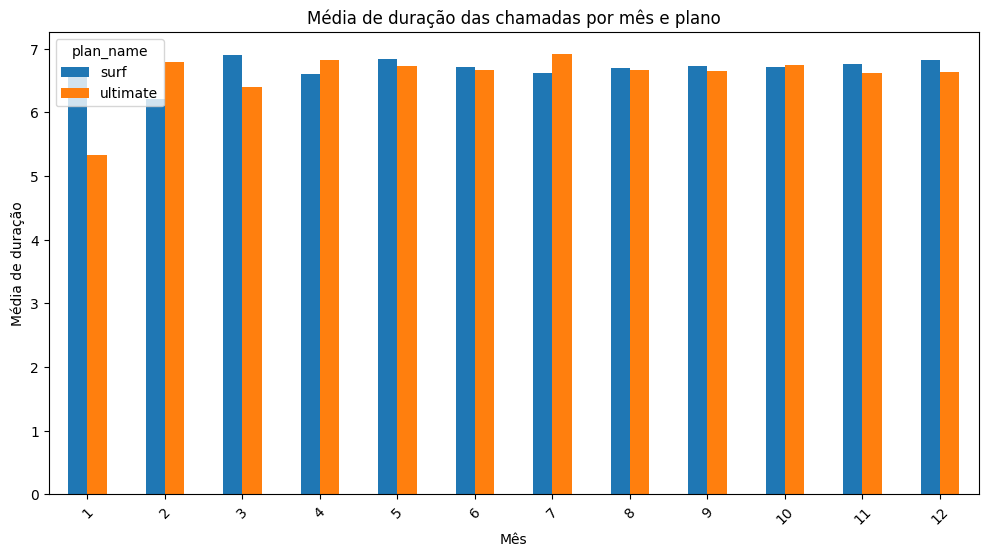

In [32]:

media_calls = calls.groupby(['user_id', 'month'])['duration'].mean()
media_calls = media_calls.reset_index()

media_calls = media_calls.merge(result_finalplans[['user_id', 'month', 'plan_name']]
)

mediacalls_mes = media_calls.groupby(['month', 'plan_name'])['duration'].mean().reset_index()

pivot = mediacalls_mes.pivot(
    index='month',
    columns='plan_name',
    values='duration'
)

pivot.plot(kind='bar', figsize=(12, 6))

plt.xlabel('Mês')
plt.ylabel('Média de duração')
plt.title('Média de duração das chamadas por mês e plano')
plt.xticks(rotation=45);






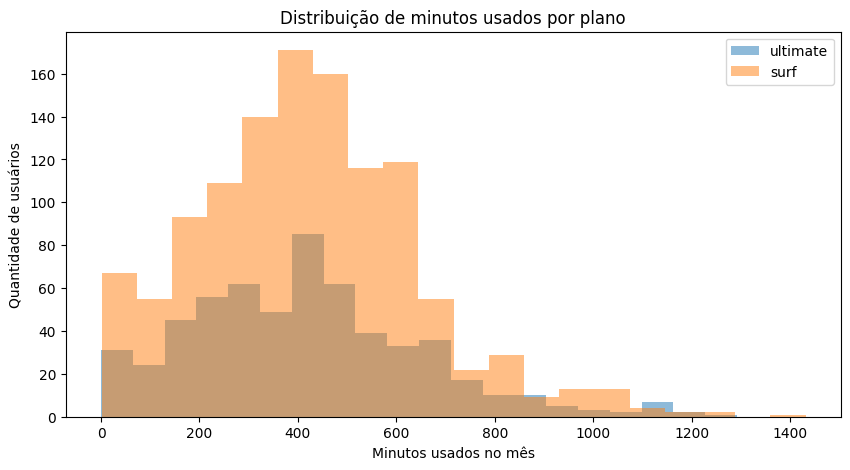

In [33]:

soma_minutes = calls.groupby(['user_id', 'month'])['duration'].sum()
soma_minutes = soma_minutes.reset_index()
soma_minutes = soma_minutes.merge(result_finalplans[['user_id', 'month', 'plan_name']])# Compare o número de minutos que os usuários de cada plano necessitam a cada mês. Construa um histograma.

plt.figure(figsize=(10, 5))

for plano in soma_minutes['plan_name'].dropna().unique():
    dados = soma_minutes[soma_minutes['plan_name'] == plano]['duration']
    plt.hist(dados, bins=20, alpha=0.5, label=plano)

plt.xlabel('Minutos usados no mês')
plt.ylabel('Quantidade de usuários')
plt.title('Distribuição de minutos usados por plano')
plt.legend()
plt.show()



[Calcule a média e a variância da duração das chamadas para refletir se os usuários de cada plano possuem comportamentos diferentes sobre as chamadas.]

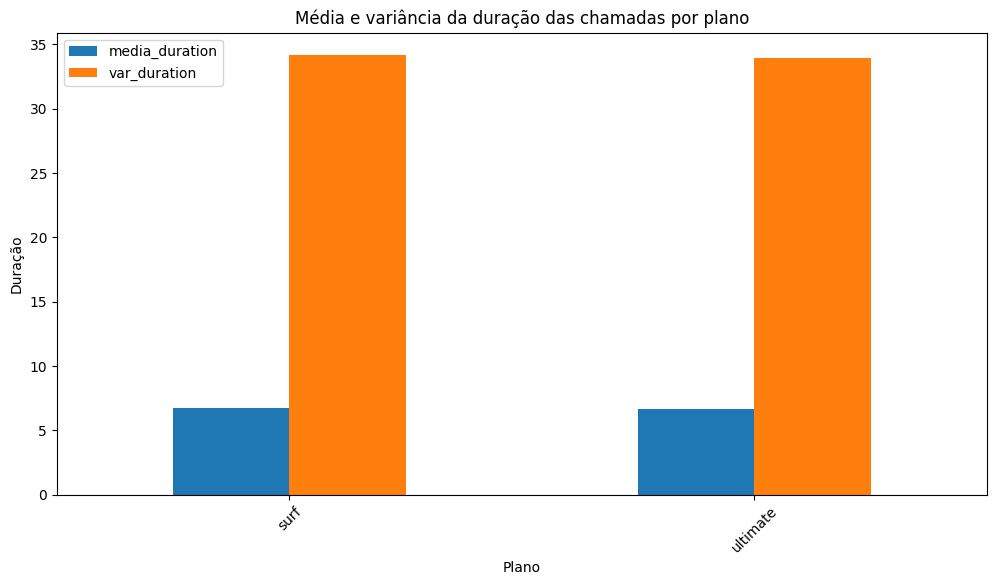

In [34]:

media_minutes = calls.groupby(['user_id', 'month'])['duration'].mean().reset_index()
media_minutes = media_minutes.rename(columns={'duration': 'media_duration'})

var_minutes = calls.groupby(['user_id', 'month'])['duration'].var().reset_index()
var_minutes = var_minutes.rename(columns={'duration': 'var_duration'})
calculo_total = media_minutes.merge(var_minutes[['user_id', 'month', 'var_duration']])
calculo_total= calculo_total.merge(result_finalplans[['user_id', 'month', 'plan_name']])
calculo_total
calculo_total = calculo_total.dropna(subset=['var_duration'])
grafico_plan = calculo_total.groupby('plan_name')[['media_duration', 'var_duration']].mean().reset_index()
pivot = grafico_plan.plot(kind='bar', figsize=(12, 6), x='plan_name')

plt.xlabel('Plano')
plt.ylabel('Duração')
plt.title('Média e variância da duração das chamadas por plano'),
plt.xticks(rotation=45);




       user_id    month  duration
count  1759.00  1759.00   1759.00
mean   1244.97     9.26    419.72
std     139.29     2.44    226.89
min    1000.00     1.00      0.00
25%    1126.00     8.00    261.55
50%    1246.00    10.00    409.11
75%    1362.00    11.00    552.14
max    1497.00    12.00   1431.22


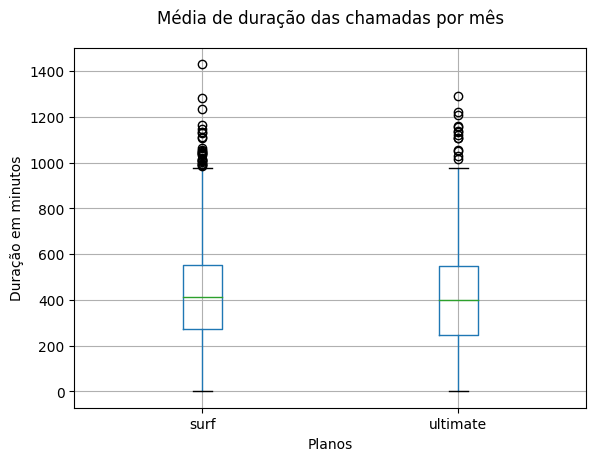

In [35]:

soma_minutes.boxplot(column='duration', by='plan_name'); # Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas
plt.suptitle('Média de duração das chamadas por mês');
plt.title('');
plt.xlabel('Planos');
plt.ylabel('Duração em minutos')

print(soma_minutes.describe().round(2))






<b> COMENTARIO DO ALUNO: </B>A média de durações de chamadas no mês são parecidas nos dois planos, só que os usuários do plano surf usam muito mais minutos minutos extras no mês, por que eles tem menos minutos free no plano. Com isso tendo uma variação muito maior, com isso gerando mais cobranças extras nos planos mesmo tendo o plano de menor valor. Tem um possivel outliers no plano surf com um valor muito alto mas preciso de mais informações para estudar.

[Formule conclusões sobre como os usuários se comportam em termos de chamadas. O comportamento é diferente dependendo do plano?]

### Mensagens

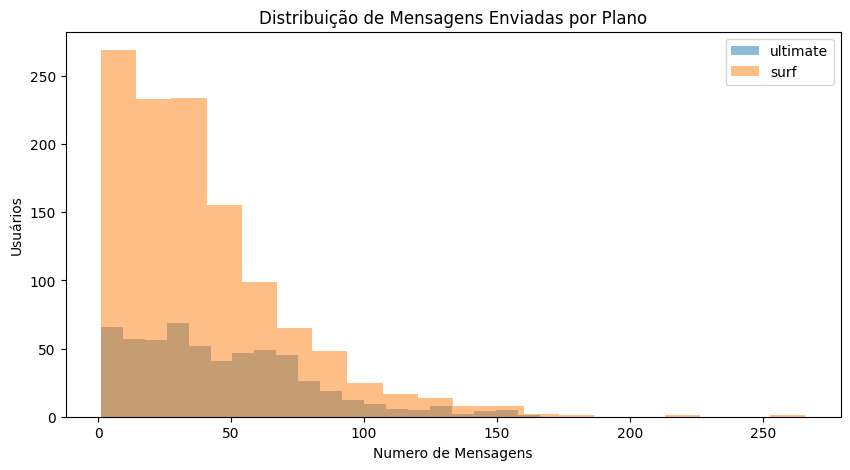

       user_id    month  total_messages
count  1759.00  1759.00         1759.00
mean   1244.97     9.26           41.78
std     139.29     2.44           32.67
min    1000.00     1.00            1.00
25%    1126.00     8.00           17.00
50%    1246.00    10.00           34.00
75%    1362.00    11.00           59.00
max    1497.00    12.00          266.00


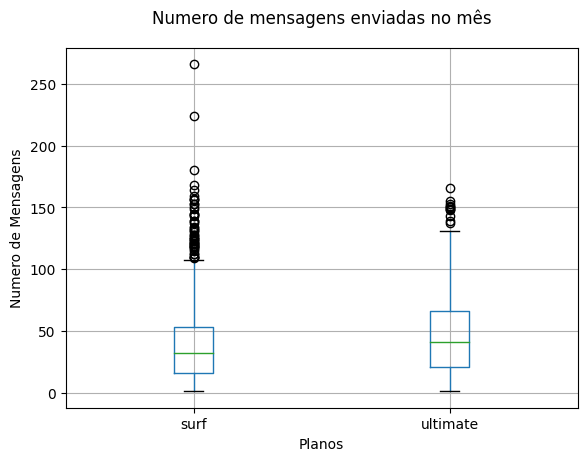

In [36]:


message_mes = messages.groupby(['user_id', 'month'])['id'].count()
message_mes = message_mes.reset_index()
message_mes = message_mes.rename(columns= {'id': 'total_messages'})


message_mes = message_mes.merge(result_finalplans[['user_id', 'month', 'plan_name']])
plt.figure(figsize=(10, 5))


for plano in message_mes['plan_name'].dropna().unique():
    dados = message_mes[message_mes['plan_name'] == plano]['total_messages']
    plt.hist(dados, bins=20, alpha=0.5, label=plano)

    plt.xlabel('Numero de Mensagens')
plt.ylabel('Usuários')
plt.title('Distribuição de Mensagens Enviadas por Plano')
plt.legend()
plt.show()

message_mes.boxplot(column='total_messages', by='plan_name');
plt.suptitle('Numero de mensagens enviadas no mês');
plt.title('');
plt.xlabel('Planos');
plt.ylabel('Numero de Mensagens');

print(message_mes.describe().round(2))


# Compare o número de mensagens que os usuários de cada plano costumam enviar a cada mês



<B>COMENTÁRIO DO ALUNO: </B> Mesmo as médias entre os dois planos sendo bem parecidas. 
Os usuarios do plano surf tendem a ultrapassar o 
numero de mensagem já os usuários do plano ultimate ficam bem a baixo do
total de numero de mensagens oferecida dentro do plano. 
Existe alguns dados que podem ser possiveis outliers ou ser estudado os dados
na coluna surf para algum usuário com um numero extra
de chamadas e mensagens enviadas por mês.

[Formule conclusões sobre como os usuários costumam consumir o tráfego da internet. O comportamento é diferente dependendo do plano?]

### Internet

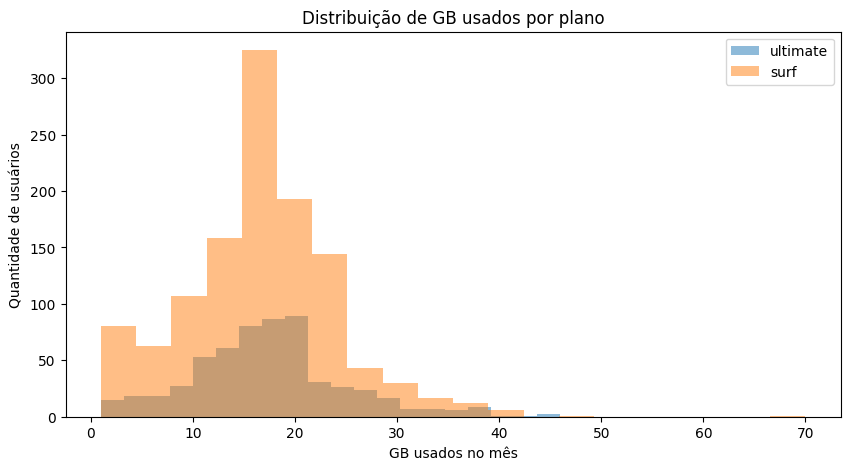

       user_id    month  gb_used
count  1759.00  1759.00  1759.00
mean   1244.97     9.26    16.95
std     139.29     2.44     7.54
min    1000.00     1.00     1.00
25%    1126.00     8.00    13.00
50%    1246.00    10.00    17.00
75%    1362.00    11.00    21.00
max    1497.00    12.00    70.00


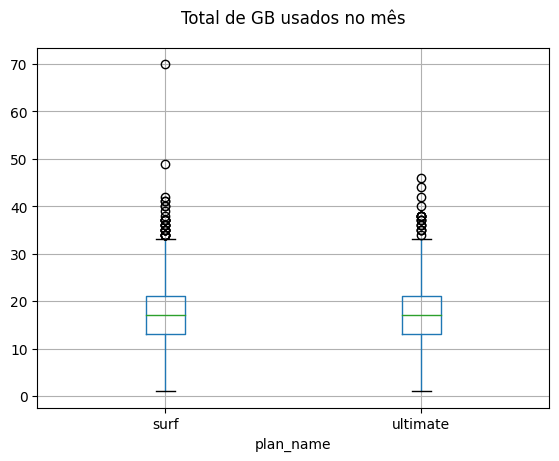

In [37]:

gb_mes = totalgb_used.merge(result_finalplans[['user_id', 'month', 'plan_name']])
plt.figure(figsize=(10, 5))


for plano in gb_mes['plan_name'].dropna().unique():
    dados = gb_mes[gb_mes['plan_name'] == plano]['gb_used']
    plt.hist(dados, bins=20, alpha=0.5, label=plano)

    plt.xlabel('GB usados no mês')
plt.ylabel('Quantidade de usuários')
plt.title('Distribuição de GB usados por plano')
plt.legend()
plt.show()


gb_mes.boxplot(column='gb_used', by='plan_name');
plt.suptitle('Total de GB usados no mês');
plt.title('');
print(gb_mes.describe().round(2))





# Compare a quantidade de tráfego de internet consumido pelos usuários por plano



[Formule conclusões sobre como os usuários tendem a consumir o tráfego da internet. O comportamento é diferente dependendo do plano?]

<B> COMENTARIO DO ALUNO:</B> Os usuários dos dois planos tem quase a mesma média e consumem quase o mesmo tanto de GB por mês 
mesmo o plano ultimate tendo o dobro de GB grátis para usar, o plano surf possui alguns dados que podem 
ser possiveis outliers e teremos que analisar o que está ocorrendo isso.

## Receita

[Da mesma forma que você estudou o comportamento dos usuários, descreva estatisticamente as receitas dos planos.]

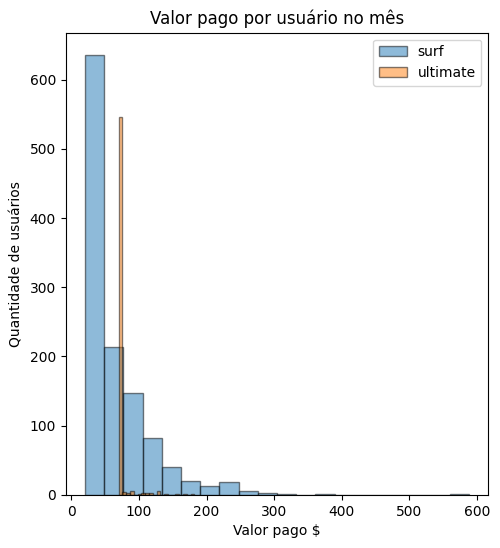

       messages_included  mb_per_month_included  minutes_included  \
count            1759.00                1759.00           1759.00   
mean              362.71               20415.96           1322.91   
std               446.54                7219.87           1175.11   
min                50.00               15360.00            500.00   
25%                50.00               15360.00            500.00   
50%                50.00               15360.00            500.00   
75%              1000.00               30720.00           3000.00   
max              1000.00               30720.00           3000.00   

       usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  \
count          1759.00     1759.00          1759.00         1759.00   
mean             36.46        9.01             0.02            0.02   
std              23.50        1.41             0.01            0.01   
min              20.00        7.00             0.01            0.01   
25%              20.00 

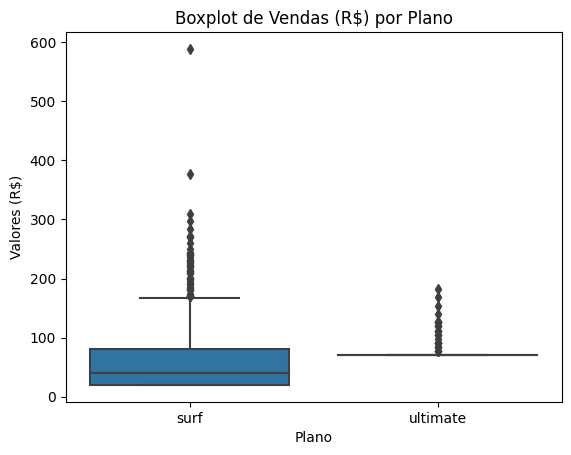

In [38]:

 plt.figure(figsize=(12, 6))
plt.subplot(1,2,1)
for plano in taxa_mensal['plan_name'].dropna().unique():
    dados = taxa_mensal[taxa_mensal['plan_name'] == plano]['monthly_pay_total']
    plt.hist(dados, bins=20, alpha=0.5, label=plano, edgecolor='black')

plt.xlabel('Valor pago $')
plt.ylabel('Quantidade de usuários')
plt.title('Valor pago por usuário no mês')
plt.legend()


plt.show()

sns.boxplot(data=taxa_mensal, x= 'plan_name', y= 'monthly_pay_total');
plt.title('');
plt.title('Boxplot de Vendas (R$) por Plano')
plt.xlabel('Plano')
plt.ylabel('Valores (R$)')

print(taxa_mensal.describe().round(2));

<B> COMENTARIO DO ALUNO: </B>A média dos dois grupos pagam o valor normal do plano,
mas no plano surf tem mais excedentes do que o ultimate,com uma receita maior 
chegando ao valor ou mais do plano ultimate.
Os usuários acabam contratando o plano menor, mas uma boa parte excedendo o valor do plano.

[Formule conclusões sobre como a receita difere entre os planos.]

## Teste hipóteses estatísticas

[Teste a hipótese de que a receita média dos usuários dos planos Ultimate e Surf são diferentes.]

H₀: A receita média dos planos Surf e Ultimate são iguais
H₁: A receita média dos planos Surf e Ultimate são diferentes



[Formule as hipóteses nula e alternativa, escolha o teste estatístico, escolha o valor alfa.]

In [49]:
plano_surf= taxa_mensal[taxa_mensal['plan_name'] == 'surf']['monthly_pay_total']
plano_ultimate= taxa_mensal[taxa_mensal['plan_name'] == 'ultimate']['monthly_pay_total']
alpha= 0.05
stat_levene, p_levene = levene(plano_surf, plano_ultimate)
print(f'Estatística de Levene: {stat_levene:.3f}, p-valor: {p_levene:.3f}')

if p_levene < 0.05:
    print("As variâncias são diferentes (usar equal_var=False no teste t).")
    equal_var = False
else:
    print("Não há evidências de variâncias diferentes (usar equal_var=True no teste t).")
    equal_var = True
    
print()

t_stat, p_val = ttest_ind(plano_surf, plano_ultimate, equal_var=equal_var)

print(f"Resultados do Teste:")
print(f"t = {t_stat:.3f}, p-valor = {p_val:.3f}")

print(f"Média Plano surf = {plano_surf.mean():.2f}, Média Plano Ultimate = {plano_ultimate.mean():.2f}")

if p_val < alpha:
    print('rejeitamos a hipótese nula e concluímos que a média entre os planos são diferentes')
else:
    print('não há evidência suficiente para afirmar que a média entre os planos são diferentes')# Teste as hipóteses



Estatística de Levene: 338.726, p-valor: 0.000
As variâncias são diferentes (usar equal_var=False no teste t).

Resultados do Teste:
t = -7.543, p-valor = 0.000
Média Plano surf = 60.01, Média Plano Ultimate = 72.25
rejeitamos a hipótese nula e concluímos que a média entre os planos são diferentes


[Formule as hipóteses nula e alternativa, escolha o teste estatístico, escolha o valor alfa.]

In [53]:
usuarios_nynj = users[users['city'].str.contains('NY-NJ')]
usuarios_outros = users[~users['city'].str.contains('NY-NJ')]
total_nynj = usuarios_nynj.merge(taxa_mensal[['user_id', 'monthly_pay_total']], on='user_id')
total_outros= usuarios_outros.merge(taxa_mensal[['user_id', 'monthly_pay_total']], on='user_id')


stat_levene, p_levene = levene(total_nynj['monthly_pay_total'], total_outros['monthly_pay_total'])
print(f'Estatística de Levene: {stat_levene:.3f}, p-valor: {p_levene:.3f}')

if p_levene < 0.05:
    print("As variâncias são diferentes (usar equal_var=False no teste t).")
    equal_var = False
else:
    print("Não há evidências de variâncias diferentes (usar equal_var=True no teste t).")
    equal_var = True
    
print()

t_stat, p_val = ttest_ind(total_nynj['monthly_pay_total'], total_outros['monthly_pay_total'], equal_var=equal_var)

print(f"Resultados do Teste:")
print(f"t = {t_stat:.3f}, p-valor = {p_val:.3f}")

print(f"Média Plano surf = {total_nynj['monthly_pay_total'].mean():.2f}, Média Plano Ultimate = {total_outros['monthly_pay_total'].mean():.2f}")

if p_val < alpha:
    print('rejeitamos a hipótese nula e concluímos que a média entre os planos são diferentes')
else:
    print('não há evidência suficiente para afirmar que a média entre os planos são diferentes')
# Teste as hipóteses


Estatística de Levene: 0.039, p-valor: 0.843
Não há evidências de variâncias diferentes (usar equal_var=True no teste t).

Resultados do Teste:
t = -2.598, p-valor = 0.009
Média Plano surf = 57.69, Média Plano Ultimate = 65.24
rejeitamos a hipótese nula e concluímos que a média entre os planos são diferentes


## Conclusão geral

[Liste suas conclusões importantes nesta seção final, certifique-se de que elas cobrem todas as decisões (suposições) importantes que você tomou e que levaram à maneira como você processou e analisou os dados.]

In [ ]:
<b> COMENTÁRIO DO ALUNO < :Mesmo o valor do plano ultimate ser maior que o plano surf, o plano surf ele acaba sendo mais rentável. 
Pois tem um rotação de venda maior e ultilizam muito mais dos servições extras,
tendo uma média de receita maior com mais usuários ultrapassando os limites free ofertado,
e a maioria dos usuários ainda mantém o plano ativo com um nivel de cancelamento do plano menor, 
Mesmo o plano surf sendo menor,a  receita média dele ficou parecida com o do ultimate.